In [1]:
import torch
import matplotlib.pyplot as plt
from torch import nn

In [2]:
weight = 3
bias = 10

device = ("cuda" if torch.cuda.is_available() else "cpu")
x = torch.arange(0, 1, 0.02, device=device).unsqueeze(dim=1)

y = x * weight + bias
x, y

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800],
         [0.2000],
         [0.2200],
         [0.2400],
         [0.2600],
         [0.2800],
         [0.3000],
         [0.3200],
         [0.3400],
         [0.3600],
         [0.3800],
         [0.4000],
         [0.4200],
         [0.4400],
         [0.4600],
         [0.4800],
         [0.5000],
         [0.5200],
         [0.5400],
         [0.5600],
         [0.5800],
         [0.6000],
         [0.6200],
         [0.6400],
         [0.6600],
         [0.6800],
         [0.7000],
         [0.7200],
         [0.7400],
         [0.7600],
         [0.7800],
         [0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[10.0000],
         [10.0600],
        

In [3]:
split = 40
x_train = x[:split]
y_train = y[:split]
x_test = x[split:]
y_test = y[split:]

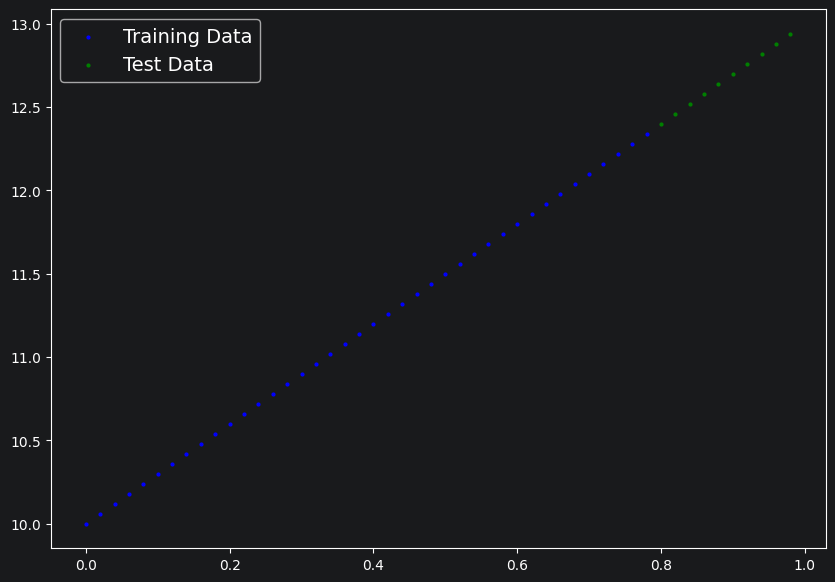

In [4]:
def plot_predictions(training_data=x_train.cpu(),
                     training_label=y_train.cpu(),
                     test_data=x_test.cpu(),
                     test_label=y_test.cpu(),
                     predictions=None):
    plt.figure(figsize=(10, 7))

    plt.scatter(training_data, training_label, c="b", s=4, label="Training Data")
    plt.scatter(test_data, test_label, c="g", s=4, label="Test Data")

    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

    plt.legend(prop={"size": 14})


plot_predictions()

In [5]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(1,
                                               requires_grad=True,
                                               device=device,
                                               dtype=torch.float))
        self.bias = nn.Parameter(torch.randn(1,
                                             requires_grad=True,
                                             device=device,
                                             dtype=torch.float
                                             ))

    def forward(self, X: torch.Tensor):
        return  self.weight * X + self.bias

In [6]:
torch.manual_seed(67)

model_0 = LinearRegressionModel()

model_0.state_dict()

OrderedDict([('weight', tensor([1.9416])), ('bias', tensor([-1.3425]))])

In [7]:
with torch.inference_mode():
    y_pred = model_0(x_test)

y_pred

tensor([[0.2108],
        [0.2496],
        [0.2885],
        [0.3273],
        [0.3661],
        [0.4049],
        [0.4438],
        [0.4826],
        [0.5214],
        [0.5603]])

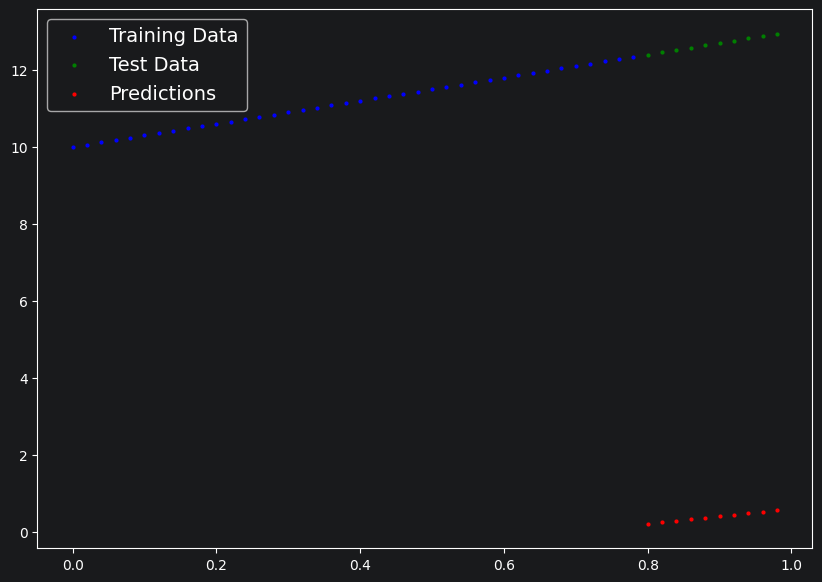

In [8]:
plot_predictions(predictions=y_pred.cpu())

In [9]:
loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.11)  ##learning rate

In [10]:
epochs = 700

epoch_count = []
train_loss_values = []
test_loss_values = []

for epoch in range(epochs):

    model_0.train()
    y_pred = model_0(x_train)
    loss = loss_fn(y_pred, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_0.eval()
    with torch.inference_mode():
        test_pred = model_0(x_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 50 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss.detach().cpu())
        test_loss_values.append(test_loss.detach().cpu())
        print(epoch, loss, test_loss)

print(model_0.state_dict())

0 tensor(11.7553, grad_fn=<MeanBackward0>) tensor(12.1363)
50 tensor(5.4187, grad_fn=<MeanBackward0>) tensor(4.7272)
100 tensor(0.5477, grad_fn=<MeanBackward0>) tensor(1.1271)
150 tensor(0.3509, grad_fn=<MeanBackward0>) tensor(0.8088)
200 tensor(0.1621, grad_fn=<MeanBackward0>) tensor(0.3689)
250 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
300 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
350 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
400 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
450 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
500 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
550 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
600 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
650 tensor(0.0920, grad_fn=<MeanBackward0>) tensor(0.0599)
OrderedDict({'weight': tensor([3.0076]), 'bias': tensor([9.9050])})


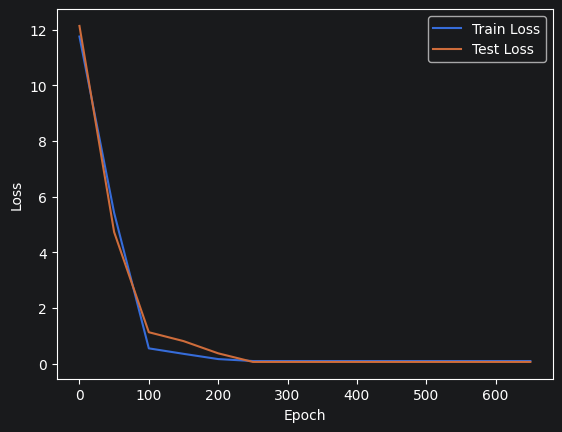

In [11]:
plt.plot(epoch_count, torch.tensor(train_loss_values), label="Train Loss")
plt.plot(epoch_count, torch.tensor(test_loss_values), label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

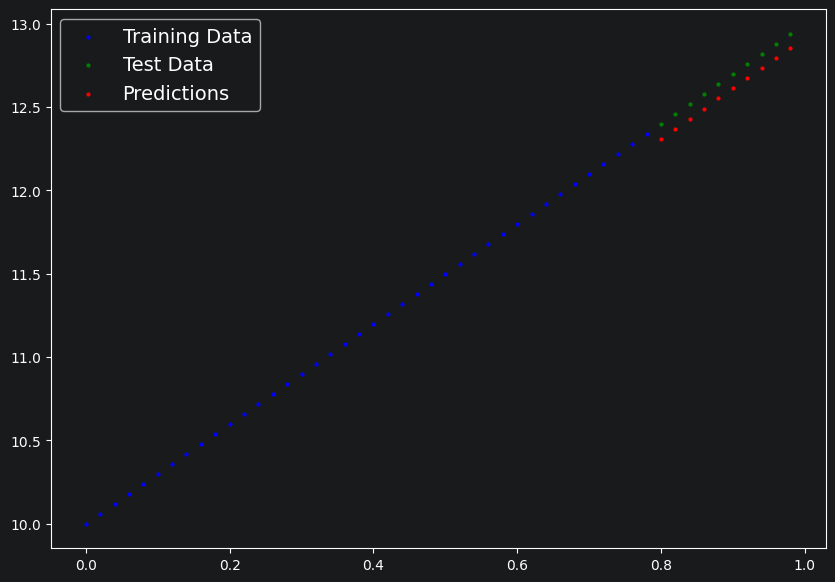

In [12]:
with torch.inference_mode():
    y_pred_new = model_0(x_test)

plot_predictions(predictions=y_pred_new.cpu())